# 02. Modelagem: previsão de churn e retorno da campanha

O objetivo é dar a cada cliente uma probabilidade de cancelamento e decidir quem recebe uma oferta de retenção, de forma que a campanha tenha o maior lucro possível.

Cuidados contra vazamento de dados:
- 20% dos clientes ficam separados como teste e só são usados uma vez, no final.
- As transformações (novas variáveis, one-hot e padronização) ficam dentro de um `sklearn.Pipeline`, ajustado só com os dados de treino de cada fold.
- O limiar de decisão é escolhido com previsões out-of-fold do treino, sem olhar o teste.

O código está em `src/churn/train.py`. Aqui eu rodo o treino e comento os resultados.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))

import pandas as pd
from IPython.display import Image, display

from churn.data import clean, load_raw
from churn.features import add_features
from churn import plots

pd.set_option("display.max_columns", 30)
FIG = RAIZ / "reports" / "figures"
import json
from churn.train import main

## 1. Treino e comparação dos modelos

In [2]:
metricas = main()

Treino: 5,634 clientes | Teste: 1,409 clientes | churn 26.5%


  Baseline (sem modelo)    ROC-AUC 0.500 ± 0.000 | PR-AUC 0.265 ± 0.000


  Regressão Logística      ROC-AUC 0.847 ± 0.012 | PR-AUC 0.660 ± 0.015


  Random Forest            ROC-AUC 0.844 ± 0.010 | PR-AUC 0.657 ± 0.024


  XGBoost                  ROC-AUC 0.847 ± 0.010 | PR-AUC 0.664 ± 0.022

Melhor modelo na validação cruzada: XGBoost


Limiar que maximiza o lucro (out-of-fold, treino): 0.20



TESTE (XGBoost, limiar 0.20): ROC-AUC 0.846 | PR-AUC 0.666 | recall 84.5% | precisão 47.8%
Lucro: modelo US$ 52,111 | limiar 0,5 US$ 39,814 | todos US$ 27,524 | aleatório US$ 13,319
Concluído em 27s


In [3]:
cv = pd.DataFrame(metricas["validacao_cruzada"]).set_index("modelo")
cv.columns = ["ROC-AUC (média)", "ROC-AUC (desvio)", "PR-AUC (média)", "PR-AUC (desvio)"]
cv.round(3)

,ROC-AUC (média),ROC-AUC (desvio),PR-AUC (média),PR-AUC (desvio)
modelo,,,,
XGBoost,0.847,0.010,0.664,0.022
Regressão Logística,0.847,0.012,0.660,0.015
Random Forest,0.844,0.010,0.657,0.024
Baseline (sem modelo),0.500,0.000,0.265,0.000


Regressão Logística, Random Forest e XGBoost ficaram praticamente empatados: as diferenças são menores que o desvio padrão entre os folds. Escolhi o XGBoost por ter a maior PR-AUC média, mas a Regressão Logística também serviria e é mais fácil de explicar. Num projeto real, eu discutiria essa escolha com a área de negócio.

Os três ficam bem acima do baseline (ROC-AUC 0,50 e PR-AUC 0,27).

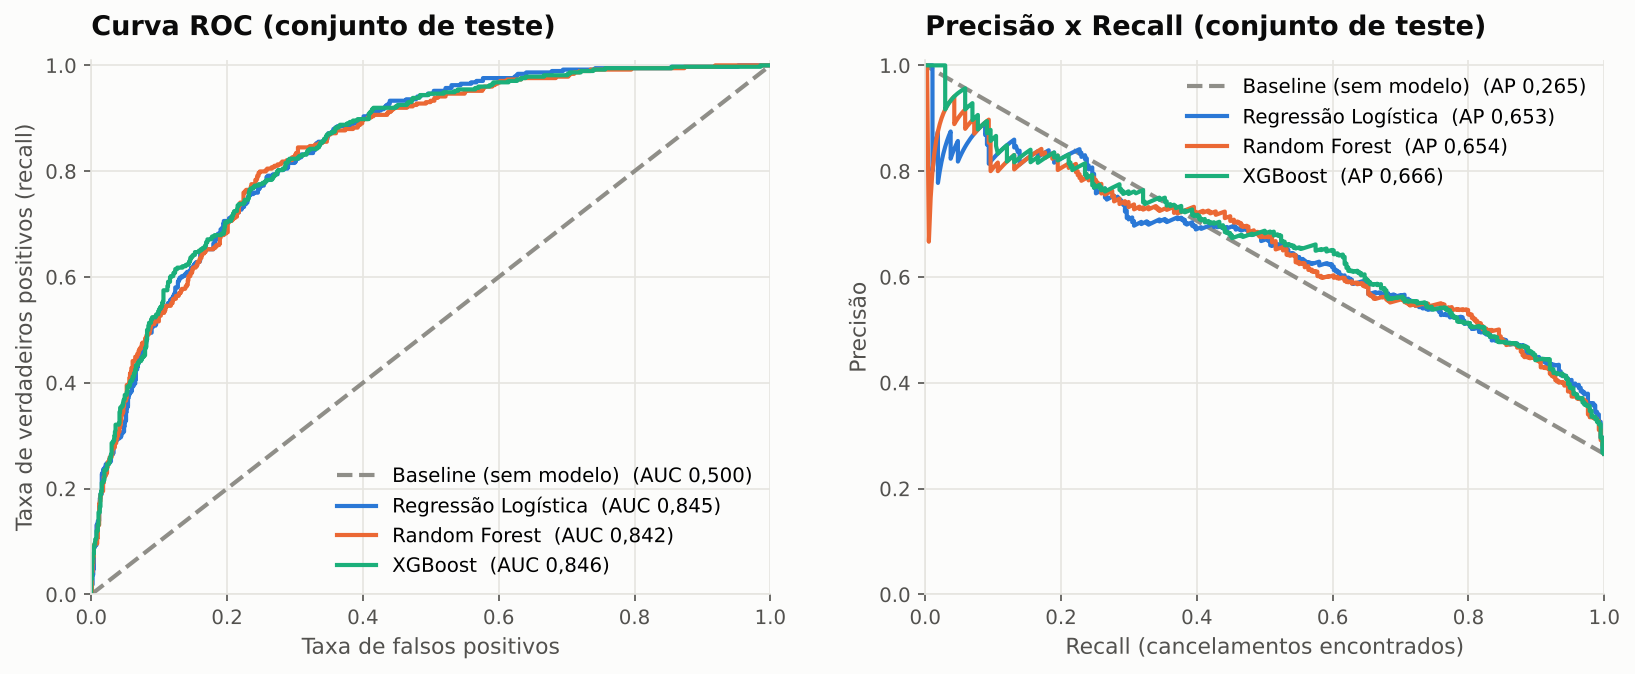

In [4]:
display(Image(FIG / "05_curvas_roc_pr.png"))

## 2. Escolha do limiar pelo lucro

O mais comum é classificar como "vai cancelar" quem tem probabilidade de 0,50 ou mais, mas esse valor não leva em conta os custos do negócio. Usei estas premissas, que podem ser alteradas em `src/churn/config.py`:

| Premissa | Valor |
|---|---|
| Custo de abordar um cliente com oferta | US$ 50 |
| Chance de a oferta reter quem iria sair | 30% |
| Receita preservada ao reter um cliente | 12 mensalidades |

Lucro = (clientes retidos × 12 mensalidades) − (clientes abordados × US$ 50)

Perder um cliente que ia cancelar custa bem mais do que abordar um cliente que ficaria. Por isso o melhor limiar fica abaixo de 0,50.

Limiar escolhido (out-of-fold no treino): 0.20


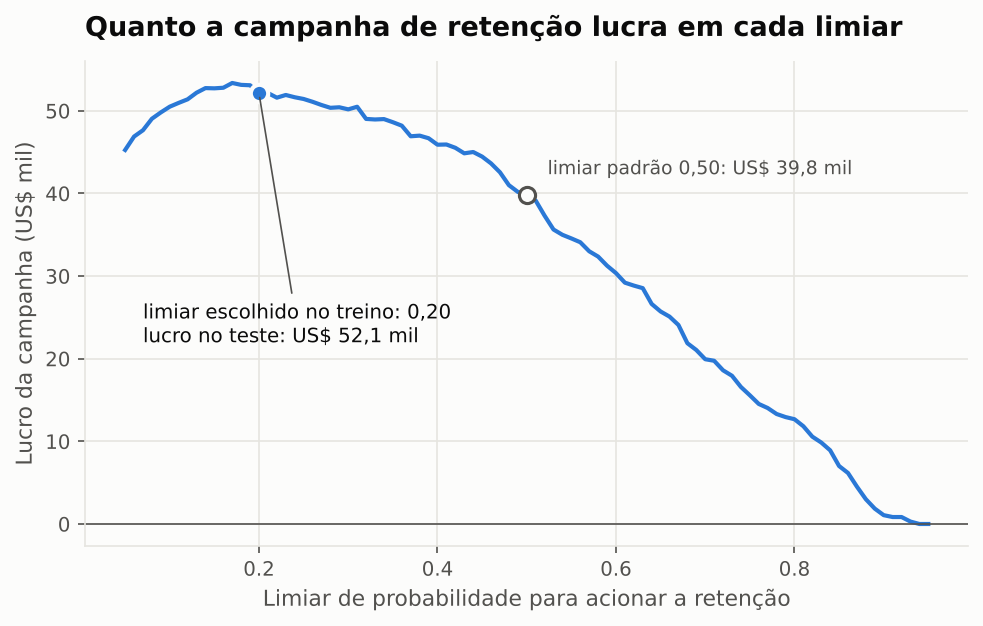

In [5]:
print(f"Limiar escolhido (out-of-fold no treino): {metricas['limiar_decisao']:.2f}")
display(Image(FIG / "07_curva_lucro.png"))

In [6]:
neg = metricas["negocio_teste"]
comparacao = pd.Series({
    "Não fazer nada": neg["lucro_nao_fazer_nada"],
    "Abordar 100% da base": neg["lucro_abordar_todos"],
    "Abordar ao acaso (mesmo volume do modelo)": neg["lucro_abordagem_aleatoria_mesmo_volume"],
    "Modelo com limiar padrão 0,50": neg["lucro_modelo_limiar_0_5"],
    "Modelo com limiar otimizado": neg["lucro_modelo_limiar_otimo"],
}, name="Lucro no teste (US$)")
comparacao.round(0).to_frame()

,Lucro no teste (US$)
Não fazer nada,0.0
Abordar 100% da base,27524.0
Abordar ao acaso (mesmo volume do modelo),13319.0
"Modelo com limiar padrão 0,50",39814.0
Modelo com limiar otimizado,52111.0


No conjunto de teste (1.409 clientes):
- Com o limiar escolhido, o lucro é de cerca de US$ 52 mil. É 31% a mais que o do mesmo modelo com limiar 0,50 e quase 4 vezes o de abordar a mesma quantidade de clientes ao acaso.
- No teste, o melhor limiar fica um pouco abaixo de 0,20. Como a curva é quase plana nessa região, o limiar escolhido no treino funcionou bem nos dados novos.

## 3. Qualidade das decisões

ROC-AUC: 0.846 | PR-AUC: 0.666
Recall: 84.5% dos cancelamentos foram identificados
Precisão: 47.8% dos abordados realmente iriam cancelar
Clientes abordados: 661 (47% da base)


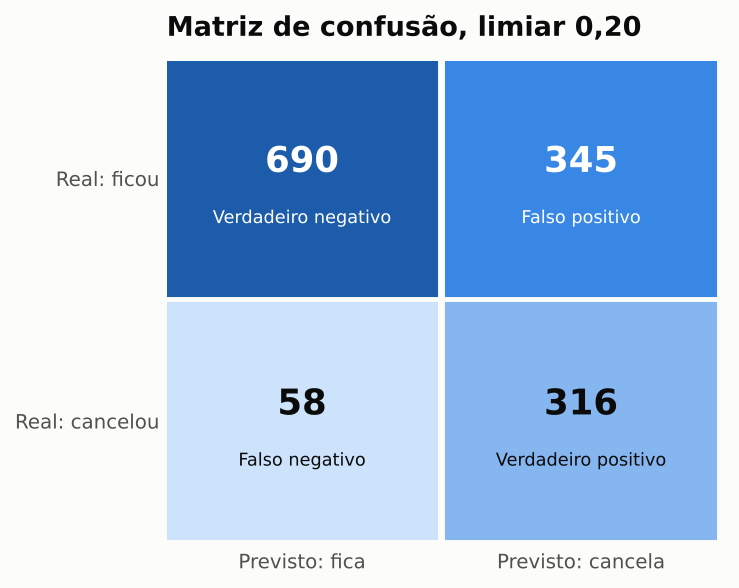

In [7]:
t = metricas["teste"]
print(f"ROC-AUC: {t['roc_auc']:.3f} | PR-AUC: {t['pr_auc']:.3f}")
print(f"Recall: {t['recall']:.1%} dos cancelamentos foram identificados")
print(f"Precisão: {t['precisao']:.1%} dos abordados realmente iriam cancelar")
print(f"Clientes abordados: {t['clientes_abordados']} ({t['pct_base_abordada']:.0%} da base)")
display(Image(FIG / "06_matriz_confusao.png"))

O modelo encontra 84,5% dos clientes que iriam cancelar e aborda 47% da base. Em troca, há falsos positivos: clientes que ficariam de qualquer jeito e recebem a oferta. A curva de lucro mostra que, com essas premissas, esse custo compensa.

## 4. Variáveis mais importantes

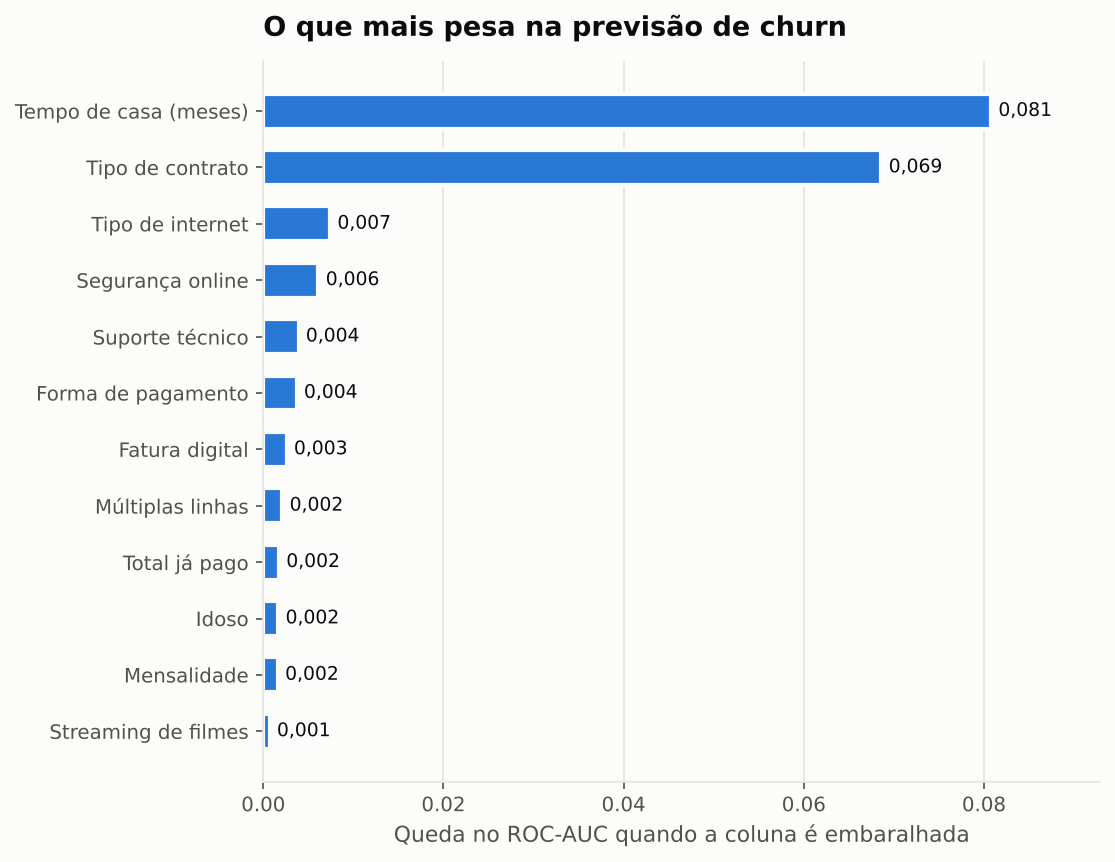

In [8]:
display(Image(FIG / "08_importancia.png"))

A importância por permutação mede quanto o ROC-AUC cai quando os valores de uma coluna são embaralhados. Tempo de casa e tipo de contrato são as variáveis que mais pesam, como na análise exploratória. As outras contribuem pouco sozinhas porque carregam informação parecida. Por exemplo, quem tem contrato mensal costuma ter pouco tempo de casa.

## 5. Limitações e próximos passos
- Os dados mostram um único momento. Faltam histórico de uso, reclamações e atendimento, que devem melhorar o modelo.
- O custo da oferta e a taxa de sucesso são estimativas. O ideal seria medir esses valores com um teste A/B.
- Próximos passos: calibrar as probabilidades, gerar explicações por cliente com SHAP, monitorar drift em produção e servir o modelo com uma API em FastAPI.